In [23]:
import torch
import os
from torchvision.transforms import v2
from torchvision import datasets
from pathlib import Path
from torch.utils.data import DataLoader
import torchvision.models as models
from tqdm.auto import tqdm
import torchinfo
from timeit import default_timer as timer
from torchinfo import summary
from typing import Dict, List
import matplotlib.pyplot as plt
import mlxtend
import torchmetrics
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix


In [47]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(size=(224, 224), antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.TrivialAugmentWide(num_magnitude_bins=20),
    v2.ToImage(), 
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
test_transform = v2.Compose([
    v2.Resize(size=(224, 224)),
    v2.CenterCrop(224),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [48]:
test_dir = Path("Data/test")
train_dir = Path("Data/train")

In [50]:
%cd OneAlpha

c:\Users\Fidel S\OneDrive\Desktop\OneAlpha\OneAlpha


In [51]:
train_data = datasets.ImageFolder(root=train_dir, transform=train_transform, target_transform=None)
test_data = datasets.ImageFolder(root=test_dir, transform=test_transform)

In [52]:
BATCH_SIZE = 8

train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              num_workers=4,
                              shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             num_workers=4,
                             shuffle=False,
                             )

In [53]:
weights = models.ResNet18_Weights.DEFAULT
model_1 = models.resnet18(weights=weights)

In [54]:
summary(model=model_1,
        input_size=(1,3,224,224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 1000]                 --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

In [55]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [56]:
def train_step(model: torch.nn.Module,
          loss_fn: torch.nn.Module,
          optimizer: torch.optim.Optimizer,
          X,
          y,
          device=None):
    model.train()

    train_loss, train_acc = 0,0

    X,y = X.to(device), y.to(device)

    y_pred = model(X)

    loss = loss_fn(y_pred, y)
    train_loss = loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    y_pred_class = torch.argmax(y_pred, dim=1)
    train_acc = (y_pred_class == y).sum().item()/len(y_pred)

    return train_loss, train_acc


In [57]:
def test_step(model: torch.nn.Module,
         loss_fn: torch.nn.Module,
         X,
         y,
         device=None):
    model.eval()

    test_loss, test_acc = 0,0

    with torch.inference_mode():
        X,y = X.to(device), y.to(device)

        y_pred = model(X)

        loss = loss_fn(y_pred, y)
        test_loss = loss.item()

        y_pred_class = torch.argmax(y_pred, dim=1)
        test_acc = (y_pred_class == y).sum().item()/len(y_pred)
        
    return test_loss, test_acc

In [58]:
MODEL_PATH = Path("Models")
MODEL_NAME = "restnet18_1"
MODEL_SAVE_PATH = MODEL_PATH/MODEL_NAME

In [59]:
def train(model: torch.nn.Module,
          loss_fn: torch.nn.Module,
          test_dataloader: torch.utils.data.DataLoader,
          train_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          epochs: int = 5,
          device=None):
    
    results = {"test_loss": [],
               "test_acc": [],
               "train_loss": [],
               "train_acc": [],
               "train_epoch_loss": [],
               "test_epoch_loss": [],
               "train_epoch_acc": [],
               "test_epoch_acc": []}
    
    for epoch in tqdm(range(epochs)):

        train_loss, train_acc = 0,0
        test_loss, test_acc = 0,0
        train_epoch_loss, train_epoch_acc = 0,0
        test_epoch_loss, test_epoch_acc = 0,0

        for batch, (X,y) in enumerate(train_dataloader):

            train_loss, train_acc = train_step(model=model,
                                               loss_fn=loss_fn,
                                               optimizer=optimizer,
                                               X=X,
                                               y=y,
                                               device=device)
            if batch != len(train_dataloader)-1:
                results["train_loss"].append(train_loss)
                results["train_acc"].append(train_acc)
                train_epoch_loss += train_loss
                train_epoch_acc += train_acc
        
        for batch, (X,y) in enumerate(test_dataloader):

            test_loss, test_acc = test_step(model=model,
                                            loss_fn=loss_fn,
                                            X=X,
                                            y=y,
                                            device=device)
            if batch != len(test_dataloader)-1:
                results["test_loss"].append(test_loss)
                results["test_acc"].append(test_acc)
                test_epoch_loss += test_loss
                test_epoch_acc += test_acc

        train_epoch_loss = train_epoch_loss/len(train_dataloader)
        test_epoch_loss = test_epoch_loss/len(test_dataloader)
        train_epoch_acc = train_epoch_acc/len(train_dataloader)
        test_epoch_acc = test_epoch_acc/len(test_dataloader)

        results["test_epoch_loss"].append(test_epoch_loss)
        results["test_epoch_acc"].append(test_epoch_acc)
        results["train_epoch_loss"].append(train_epoch_loss)
        results["train_epoch_acc"].append(train_epoch_acc)
        
        torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)
        
        print(f"Epoch: {epoch+1} | train_loss: {train_epoch_loss:.4f} | train_acc: {train_epoch_acc:.4f} | test_loss: {test_epoch_loss:.4f} | test_acc: {test_epoch_acc:.4f}")

        
    return results

In [60]:
loaded_model = model_1
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [61]:
EPOCHS = 10

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.0001)

start_time = timer()

model_1_results = train(loss_fn = loss_fn,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader,
                        epochs = EPOCHS,
                        device=device,
                        model=loaded_model)

end_time = timer()

print(f"Total training time: {end_time-start_time:.3f} seconds")

 10%|█         | 1/10 [14:52<2:13:52, 892.50s/it]

Epoch: 1 | train_loss: 2.3997 | train_acc: 0.4241 | test_loss: 1.3515 | test_acc: 0.6396


 20%|██        | 2/10 [29:41<1:58:44, 890.55s/it]

Epoch: 2 | train_loss: 2.3028 | train_acc: 0.4436 | test_loss: 1.3325 | test_acc: 0.6446


 30%|███       | 3/10 [44:46<1:44:39, 897.13s/it]

...

Epoch: 8 | train_loss: 2.1452 | train_acc: 0.4762 | test_loss: 1.3101 | test_acc: 0.6494


 90%|█████████ | 9/10 [2:09:05<14:11, 851.28s/it]

Epoch: 9 | train_loss: 2.1362 | train_acc: 0.4771 | test_loss: 1.2943 | test_acc: 0.6547


100%|██████████| 10/10 [2:23:28<00:00, 860.83s/it]

Epoch: 10 | train_loss: 2.1303 | train_acc: 0.4763 | test_loss: 1.2945 | test_acc: 0.6531
Total training time: 8608.331 seconds


In [41]:
loaded_model = model_1
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [62]:
def plot_loss_curves(results: Dict[str, List[float]]):
    train_loss = results["train_epoch_loss"]
    test_loss = results["test_epoch_loss"]
    train_acc = results["train_epoch_acc"]
    test_acc = results["test_epoch_acc"]

    test_batch = range(len(results["test_epoch_loss"]))
    train_batch = range(len(results["train_epoch_loss"]))

    plt.figure(figsize=(15,7))

    plt.subplot(1,2,1)
    plt.plot(train_batch, train_loss, label="train_loss")
    plt.plot(test_batch, test_loss, label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(train_batch, train_acc, label="train_accuracy")
    plt.plot(test_batch, test_acc, label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

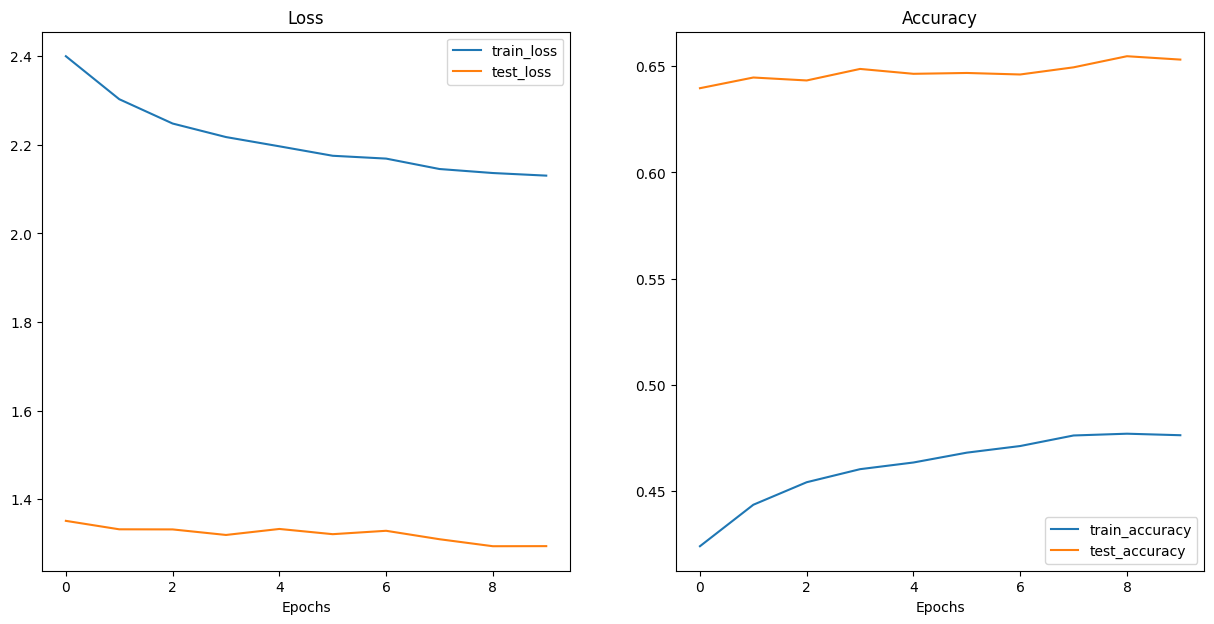

In [63]:
plot_loss_curves(model_1_results)

In [45]:
loaded_model.eval()

y_preds = []
y_pred = 0
test_acc = 0
with torch.inference_mode():
    for X,y in tqdm(test_dataloader):
        X,y = X.to(device), y.to(device)

        y_pred = loaded_model(X)

        y_pred_class = torch.argmax(y_pred, dim=1)
        y_preds.append(y_pred_class.cpu())
        test_acc += (y_pred_class == y).sum().item()
test_acc = test_acc/len(test_dataloader.dataset)

100%|██████████| 3157/3157 [03:11<00:00, 16.50it/s]


In [46]:
test_acc

0.6536237623762376

In [44]:
y_pred_tensor = torch.cat(y_preds)
class_names = train_data.classes
confmat = ConfusionMatrix(num_classes=101, task="multiclass")
confmat_tensor = confmat(preds=y_pred_tensor, target=torch.tensor(test_data.targets))
fig, ax = plot_confusion_matrix(conf_mat=confmat_tensor.numpy(),
                                class_names=class_names,
                                figsize=(100,100))